In [4]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



In [5]:
# 1 Generate synthetic data
np.random.seed(42)
X = np.linspace(0,4,50)
y = 3*np.exp(0.5*X) + np.random.normal(scale=2,size=50)

# Put into dataframe for clarity
df = pd.DataFrame({'X': X, 'y': y})

In [6]:
# 2 Transform to linear form: ln(y) = ln(a) + bX
df['ln_y'] = np.log(df['y'])

In [7]:
# 3 Apply normal equation to find coefficients
X_mat = np.vstack([np.ones(len(df)), df['X']]).T
y_vec = df["ln_y"].values

# beta = (X^T * X)^(-1) * X^T * y
beta = np.linalg.inv(X_mat.T @ X_mat) @ (X_mat.T @ y_vec)
ln_a,b = beta
a = np.exp(ln_a)

print(f"Fitted model: y = {a:.4f} * e^({b:.4f} * X)")

Fitted model: y = 2.8322 * e^(0.4880 * X)


In [8]:
# 4 Predictions
df['y_pred'] = a * np.exp(b * df['X'])
df['y_pred'].head()

0    2.832153
1    2.947263
2    3.067050
3    3.191707
4    3.321429
Name: y_pred, dtype: float64

In [13]:
# 5 Metrics (MAE, MSE, RMSE, R2)
mae = np.mean(np.abs(df['y'] - df['y_pred']))
mse = np.mean((df['y'] - df['y_pred']) ** 2)
rmse = np.sqrt(mse)
ss_total = np.sum((df['y'] - np.mean(df['y'])) ** 2)
ss_res = np.sum((df['y'] - df['y_pred']) ** 2)
r2 = 1 - (ss_res / ss_total)

# Print metrics
print("Evaluation Metrics:")
print(f"MAE: {mae:.4f}\nMSE: {mse:.4f}\nRMSE: {rmse:.4f}\nR2: {r2:.4f}")

Evaluation Metrics:
MAE: 1.5473
MSE: 3.6043
RMSE: 1.8985
R2: 0.8828


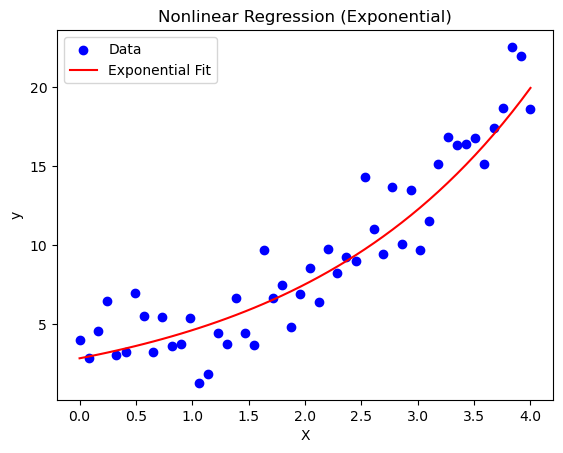

In [12]:
# 6. Plot
plt.Figure(figsize=(8,5))
plt.scatter(df["X"], df["y"], label="Data", color="blue")
plt.plot(df["X"], df["y_pred"], label="Exponential Fit", color="red")
plt.xlabel("X")
plt.ylabel("y")
plt.title("Nonlinear Regression (Exponential)")
plt.legend()
plt.show()